# Week 9, Tuesday

* No homework due this week
* Last homework due Friday of Week 10 (posted soon)
* Final project due during Finals week

## Starting Code

These were our goals.  So far we accomplished the first one.
* Increase the number of predictors from 1 to 4;
* Incorporate a stopping condition;
* Use mini-batches within each epoch, rather than using all training data simultaneously in each epoch.

We'll start with our code from the end of class last week.

In [1]:
from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression
import numpy as np

In [22]:
# removed the previous reshape line, since we need 4 columns to go with 4 features
n = 100
x, y, coef = make_regression(n_samples=n, n_features=4, random_state=0, noise=10, bias=-5, coef=True)

In [3]:
# MSE loss function
def L(w,b,x,y):
    error = x@w+b-y
    return (error**2).mean()

In [ ]:
# Define the partial wrt b manually
# important to use mean rather than (1/n) for when we use mini-batches of size < n
def Lb(w,b,x,y):
    error = x@w+b-y
    return (2*error).mean()

In [5]:
# Define the partial wrt the four weights manually
def Lw(w,b,x,y):
    error = (x@w+b-y).reshape(-1,1) # reshape to make compatible with x
    return (2*error*x).mean(axis=0)

In [6]:
x.shape

(100, 4)

In [20]:
import warnings

In [33]:
rng = np.random.default_rng(seed=0)

In [36]:
rng.permutation(100)

array([56,  7, 71, 33, 84, 98, 31, 26, 38, 74, 60,  0, 69, 21, 55, 92, 83,
       40, 61, 91, 62, 46,  4, 20, 54, 57, 76,  6, 39, 79, 93, 65, 63, 96,
        5, 34, 73, 70, 10, 58, 13, 35, 45, 27, 95, 81, 36, 59, 23, 17, 68,
       24, 80, 15, 25, 41, 78, 75, 42, 14, 19, 90, 72, 53, 94, 50, 32,  9,
       28, 85, 18, 97, 22,  3, 87, 16, 47, 43, 88,  8, 64, 77, 82, 30, 86,
       66, 89, 29, 44,  1, 67,  2, 12, 49, 11, 99, 48, 37, 52, 51])

In [39]:
x[:5]

array([[ 0.42625873,  0.67690804, -2.06998503,  1.49448454],
       [-1.33425847, -1.34671751, -0.46071979,  0.66638308],
       [-0.91282223,  1.11701629,  0.94447949,  2.38314477],
       [ 0.74718833, -1.18894496,  0.94326072, -0.70470028],
       [-0.1359497 ,  1.13689136, -1.06001582,  2.3039167 ]])

In [44]:
# random starting values
w = np.array([0.1, 0.3, -0.2, -0.4])
b = 10

rng = np.random.default_rng(seed=0)

# how do these parameters affect the number of epochs needed / likelihood of convergence
# before max_epochs
learn_rate = 0.001
max_epochs = 10000 # like max_iter in sklearn
tol = 0.0001 # smaller this number, the more stability we require

# how many of our data points do we use at each update?
# each epoch still uses all data points
mini_size = 20

for i in range(max_epochs):
    # beginning or end of for loop for this check both have advantages and disadvantages
    if i%10 == 0:
        current_loss = L(w, b, x, y)
        if i == 0:
            previous_loss = current_loss
        elif abs(current_loss - previous_loss) < tol:
            break
        else:
            previous_loss = current_loss
    shuffled_rows = rng.permutation(n)
    for j in range(0, n, mini_size):
        mini_rows = shuffled_rows[j:j+mini_size]
        grad_w = Lw(w, b, x[mini_rows], y[mini_rows])
        grad_b = Lb(w, b, x[mini_rows], y[mini_rows])
        w = w - learn_rate*grad_w
        b = b - learn_rate*grad_b
else:
    warnings.warn(f"Our stopping condition was not met in {max_epochs} epochs")

In [43]:
i

270

In [9]:
w

array([66.84139302, 86.97057685, 35.23205545, 20.37812861])

In [10]:
b

np.float64(-4.821692959442646)

In [11]:
reg = LinearRegression()

In [12]:
reg.fit(x,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[66.9 ,86.99,35.19,20.35]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-4.817
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](4,)","[11.11,10.37, 9.53, 7.93]"


In [13]:
reg.coef_

array([66.90066686, 86.98832101, 35.19092655, 20.35441935])

In [14]:
reg.intercept_

np.float64(-4.816926917434882)

## PCA with handwritten digits

If we have extra time in today's class, I want to show a demonstration of using PCA with handwritten digits.

In [15]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [45]:
from sklearn.datasets import load_digits
import matplotlib.pyplot as plt
import seaborn as sns

In [46]:
digits = load_digits()

In [47]:
X = digits.data
y = digits.target

In [49]:
X.shape

(1797, 64)

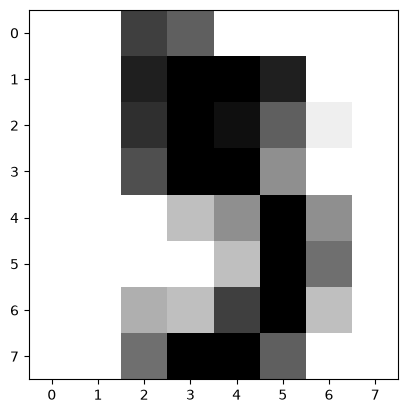

In [48]:
fig, ax = plt.subplots()
ax.imshow(X[5].reshape((8,8)), cmap="binary");

In [50]:
from sklearn.decomposition import PCA

In [75]:
# will reduce from 64 to 2 dimensions
pca = PCA(n_components=2)

Look only at the data points corresponding to 0, 2, or 8.

In [76]:
bool_ser = (y == 0) | (y == 2) | (y == 8)

In [77]:
X_sub = X[bool_ser]
y_sub = y[bool_ser]

In [78]:
X_sub.shape

(529, 64)

In [79]:
y_sub.shape

(529,)

In [80]:
y_sub[:20]

array([0, 2, 8, 0, 2, 8, 0, 2, 8, 0, 0, 8, 8, 0, 0, 2, 2, 8, 2, 0])

In [81]:
# first fit, then transform, all in one method
X_transform = pca.fit_transform(X_sub)

In [82]:
X_transform.shape

(529, 2)

In [83]:
pca.explained_variance_ratio_

array([0.30180239, 0.12638097])

In [85]:
y_sub[:10]

array([0, 2, 8, 0, 2, 8, 0, 2, 8, 0])

<Axes: >

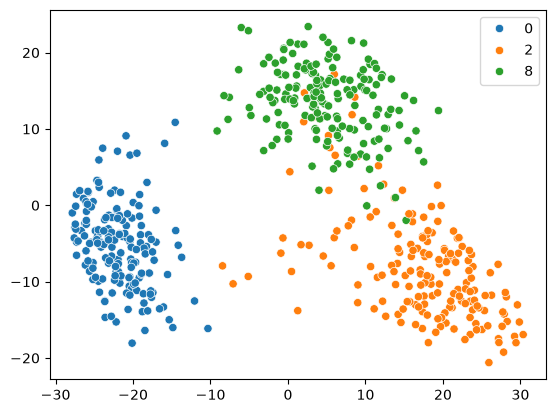

In [86]:
sns.scatterplot(
    x=X_transform[:, 0],
    y=X_transform[:, 1],
    hue=y_sub,
    palette="tab10"
)

In [87]:
pca.components_

array([[-4.81255212e-20,  2.40999580e-02,  1.46924444e-01,
         2.64723334e-02, -6.06353323e-02, -2.58573270e-02,
         1.11657011e-03, -1.08192110e-25,  6.54732399e-04,
         1.14610639e-01,  3.79282798e-02, -3.30531771e-02,
         1.85750382e-02, -1.61216249e-01, -1.37335325e-02,
        -0.00000000e+00,  1.98765693e-04,  2.56254363e-02,
        -1.43551288e-01,  9.25731684e-03,  2.65388339e-01,
        -1.65018140e-01, -8.29595660e-02, -0.00000000e+00,
        -0.00000000e+00, -1.09653890e-01, -2.51850350e-01,
         1.32872284e-01,  3.28157162e-01, -1.48067529e-01,
        -1.58762999e-01, -0.00000000e+00, -0.00000000e+00,
        -1.43681594e-01, -2.36333912e-01,  2.50849647e-01,
         2.69122695e-01, -1.90232825e-01, -1.75943054e-01,
        -0.00000000e+00, -0.00000000e+00, -7.60447405e-02,
        -1.68715490e-01,  2.57068716e-01,  1.51133061e-01,
        -2.23935360e-01, -1.20774373e-01,  2.90367676e-04,
         7.82112458e-05,  1.32123633e-02, -2.47067810e-0

In [88]:
pca.components_.shape

(2, 64)